# 06 — Selección de Características
## Pipeline CAD-TBX11K | Diagnóstico Asistido por Computador en Tuberculosis

Este notebook determina cuáles de las **3300 características** extraídas en el notebook 05
son más informativas para distinguir entre las clases `health`, `sick` y `tb`, y en qué
cantidad.

### Motivación

Con 8400 muestras y 3300 características la relación muestras/features es desfavorable
para muchos clasificadores. Conservar todas las características no implica mejor
desempeño: características redundantes, correlacionadas o poco informativas pueden
perjudicar el entrenamiento. El objetivo es determinar experimentalmente qué subconjunto
de características ofrece el mejor equilibrio entre poder discriminativo y dimensionalidad.

### Métodos comparados

| Método | Qué mide | Nota |
|--------|----------|------|
| Chi-cuadrado (χ²) | Dependencia estadística feature ↔ clase | Requiere valores no negativos (MinMaxScaler) |
| Mutual Information | Información compartida feature ↔ clase, incluyendo relaciones no lineales | No requiere escalado |
| Random Forest importance | Contribución a la reducción de impureza promedio en los árboles | Selecciona exactamente N features en cada fold |

### Decisiones de diseño

- **Split primero**: el conjunto de test (20 %) queda reservado y no interviene en
  ninguna decisión de selección. Se toca únicamente en el notebook de evaluación final.
- **Selección dentro del CV**: los tres métodos ajustan el selector dentro de cada fold
  de entrenamiento, evitando data leakage del fold de validación.
- **RF selecciona exactamente N features**: se implementa `RFTopNSelector`, un transformador
  personalizado que entrena el RF en el fold y toma los top-N índices por importancia,
  garantizando que los tres métodos son comparables en número de features.
- **Evaluador**: `LogisticRegression` dentro del CV — rápido y suficiente como proxy
  de separabilidad lineal de las features seleccionadas.
- **Rango de N**: `[100, 300, 500, 1000, 1500, 2000, 2500, 3300]` — cubre todo el
  espectro desde selecciones agresivas hasta el vector completo, permitiendo observar
  dónde se estabiliza el F1 y justificar la elección del N óptimo con evidencia.
- **CV**: 3 folds estratificados — equilibrio entre robustez y coste computacional.

### Flujo del notebook

```
features_tbx11k.csv (8400 x 3303)
         |
         v
Split 80/20 estratificado
         |
         +--------------> TEST (1680)  reservado hasta el notebook de evaluacion final
         |
         v
     TRAIN (6720)
         |
         v
 Comparacion de metodos x N (CV 3-fold, evaluador LogisticRegression)
 N = [100, 300, 500, 1000, 1500, 2000, 2500, 3300]
         |
         v
 Mejor metodo + N  ->  refit sobre TODO train
         |
         v
 Guardar splits seleccionados
   data/X_train_selected.csv
   data/X_test_selected.csv
   data/y_train.csv
   data/y_test.csv
   data/selected_feature_names.json
         |
         v
     Notebook 07
  SMOTE + modelos ML
```


## 0. Configuración del entorno

In [1]:
# Se configura el path del proyecto y se importan las librerías necesarias.
# No se importa nada de src/ porque este notebook opera directamente
# sobre el CSV de características ya generado.

import sys, os, warnings, json
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import Pipeline

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.visualization import set_publication_style

# Semilla global para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

set_publication_style()
print('Entorno configurado correctamente.')

Entorno configurado correctamente.


## 1. Carga del DataFrame de características

In [2]:
# Se carga el CSV generado por el notebook 05.
# Si aún no existe, ejecutar primero ese notebook.

CSV_PATH = Path('..') / 'data' / 'features_tbx11k.csv'

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f'No se encontró {CSV_PATH.resolve()}. '
        'Ejecuta primero el notebook 05 para generar features_tbx11k.csv'
    )

df = pd.read_csv(CSV_PATH)
print(f'CSV cargado desde: {CSV_PATH.resolve()}')
print(f'Shape: {df.shape}')
print()
print('Distribución de clases:')
print(df['class_name'].value_counts())

CSV cargado desde: C:\Users\estra\Desktop\Tuberculosis\cad-tbx11k\data\features_tbx11k.csv
Shape: (8400, 3303)

Distribución de clases:
class_name
health    3800
sick      3800
tb         800
Name: count, dtype: int64


## 2. Preparación: separar features, etiquetas y split train/test

In [3]:
# Se separan las columnas de metadatos de las columnas de features.
# El split es estratificado (misma proporción de clases en train y test)
# con 80 % train / 20 % test.
#
# El conjunto de test queda completamente reservado: no interviene en
# ninguna decisión de selección de features ni en el ajuste de scalers.
# Se utilizará únicamente en el notebook de evaluación final.

META_COLS = ['image_path', 'class_name', 'label']
feat_cols = [c for c in df.columns if c not in META_COLS]

X = df[feat_cols].values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f'Train : {X_train.shape[0]} muestras')
print(f'Test  : {X_test.shape[0]} muestras  (reservado)')
print()
print('Distribución en train:')
unique, counts = np.unique(y_train, return_counts=True)
for cls, cnt in zip(unique, counts):
    print(f'  clase {cls}: {cnt}')
print()
print('Distribución en test:')
unique, counts = np.unique(y_test, return_counts=True)
for cls, cnt in zip(unique, counts):
    print(f'  clase {cls}: {cnt}')

Train : 6720 muestras
Test  : 1680 muestras  (reservado)

Distribución en train:
  clase 0: 3040
  clase 1: 3040
  clase 2: 640

Distribución en test:
  clase 0: 760
  clase 1: 760
  clase 2: 160


## 3. Experimento de selección: método × N con validación cruzada

In [4]:
# Para cada combinación (método, N) se evalúa el F1-macro mediante
# validación cruzada de 3 folds sobre el train.
#
# Los tres métodos ajustan el selector DENTRO de cada fold usando
# sklearn Pipeline, lo que garantiza que ningún método ve información
# del fold de validación durante la selección.
#
# Para RF se define RFTopNSelector: un transformador personalizado que
# entrena un Random Forest en el fold y selecciona EXACTAMENTE las top-N
# features por importancia. Esto garantiza que los tres métodos son
# comparables: todos seleccionan el mismo número de features para cada N.
#
# El rango N = [100, 300, 500, 1000, 1500, 2000, 2500, 3300] cubre todo
# el espectro para identificar dónde se estabiliza el F1 y en qué punto
# añadir más características deja de aportar mejoras significativas.

class RFTopNSelector(BaseEstimator, TransformerMixin):
    """Selecciona exactamente las top-N features por importancia de Random Forest.

    Entrena un RandomForestClassifier en cada llamada a fit() y selecciona
    los top-N índices por importancia. Siempre devuelve exactamente N features,
    lo que hace la comparación con Chi² y MI directamente comparable.
    """
    def __init__(self, n_features=100, n_estimators=100, random_state=42):
        self.n_features   = n_features
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y=None):
        rf = RandomForestClassifier(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=-1,
        )
        rf.fit(X, y)
        self.top_idx_ = np.argsort(rf.feature_importances_)[::-1][:self.n_features]
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return X[:, self.top_idx_]


N_VALUES   = [100, 300, 500, 1000, 1500, 2000, 2500, 3300]
CV_FOLDS   = 3
cv         = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
lr_params  = dict(max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)

results = []  # lista de dicts con (method, n, mean_f1, std_f1)

# ── Chi-cuadrado ──────────────────────────────────────────────────────────────
# Chi² requiere valores no negativos → MinMaxScaler dentro del pipeline.
# Cuando N = 3300 (todas las features), SelectKBest con k='all' es equivalente.
print('Evaluando Chi-cuadrado...')
for n in N_VALUES:
    k = 'all' if n == X_train.shape[1] else n
    pipe = Pipeline([
        ('scaler',    MinMaxScaler()),
        ('selector',  SelectKBest(chi2, k=k)),
        ('std',       StandardScaler()),
        ('clf',       LogisticRegression(**lr_params)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    results.append({'method': 'Chi2', 'n': n, 'mean_f1': scores.mean(), 'std_f1': scores.std()})
    print(f'  N={n:4d}  F1-macro={scores.mean():.4f} +/- {scores.std():.4f}')

# ── Mutual Information ────────────────────────────────────────────────────────
print('Evaluando Mutual Information...')
for n in N_VALUES:
    k = 'all' if n == X_train.shape[1] else n
    pipe = Pipeline([
        ('selector',  SelectKBest(mutual_info_classif, k=k)),
        ('std',       StandardScaler()),
        ('clf',       LogisticRegression(**lr_params)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    results.append({'method': 'MI', 'n': n, 'mean_f1': scores.mean(), 'std_f1': scores.std()})
    print(f'  N={n:4d}  F1-macro={scores.mean():.4f} +/- {scores.std():.4f}')

# ── Random Forest importance (exactamente N features, dentro de cada fold) ────
# Cuando N = 3300 (todas las features), RFTopNSelector toma todos los índices
# en orden de importancia, equivalente a no filtrar.
print('Evaluando RF importance (exactamente N features, dentro de cada fold)...')
for n in N_VALUES:
    pipe = Pipeline([
        ('selector',  RFTopNSelector(n_features=n, n_estimators=100, random_state=RANDOM_STATE)),
        ('std',       StandardScaler()),
        ('clf',       LogisticRegression(**lr_params)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    results.append({'method': 'RF', 'n': n, 'mean_f1': scores.mean(), 'std_f1': scores.std()})
    print(f'  N={n:4d}  F1-macro={scores.mean():.4f} +/- {scores.std():.4f}')

results_df = pd.DataFrame(results)
print()
print('Resultado completo:')
print(results_df.to_string(index=False))

Evaluando Chi-cuadrado...
  N= 100  F1-macro=0.8373 +/- 0.0090
  N= 300  F1-macro=0.8704 +/- 0.0035
  N= 500  F1-macro=0.8823 +/- 0.0107
  N=1000  F1-macro=0.9127 +/- 0.0104
  N=1500  F1-macro=0.9208 +/- 0.0053
  N=2000  F1-macro=0.9273 +/- 0.0066
  N=2500  F1-macro=0.9302 +/- 0.0060
  N=3300  F1-macro=0.9314 +/- 0.0084
Evaluando Mutual Information...
  N= 100  F1-macro=0.8889 +/- 0.0077
  N= 300  F1-macro=0.9008 +/- 0.0004
  N= 500  F1-macro=0.8999 +/- 0.0034
  N=1000  F1-macro=0.9123 +/- 0.0082
  N=1500  F1-macro=0.9217 +/- 0.0058
  N=2000  F1-macro=0.9259 +/- 0.0073
  N=2500  F1-macro=0.9288 +/- 0.0074
  N=3300  F1-macro=0.9314 +/- 0.0084
Evaluando RF importance (exactamente N features, dentro de cada fold)...
  N= 100  F1-macro=0.9051 +/- 0.0106
  N= 300  F1-macro=0.9129 +/- 0.0086
  N= 500  F1-macro=0.9170 +/- 0.0065
  N=1000  F1-macro=0.9285 +/- 0.0040
  N=1500  F1-macro=0.9313 +/- 0.0032
  N=2000  F1-macro=0.9354 +/- 0.0039
  N=2500  F1-macro=0.9297 +/- 0.0053
  N=3300  F1-macro

## 4. Visualización: curva N vs F1-macro por método

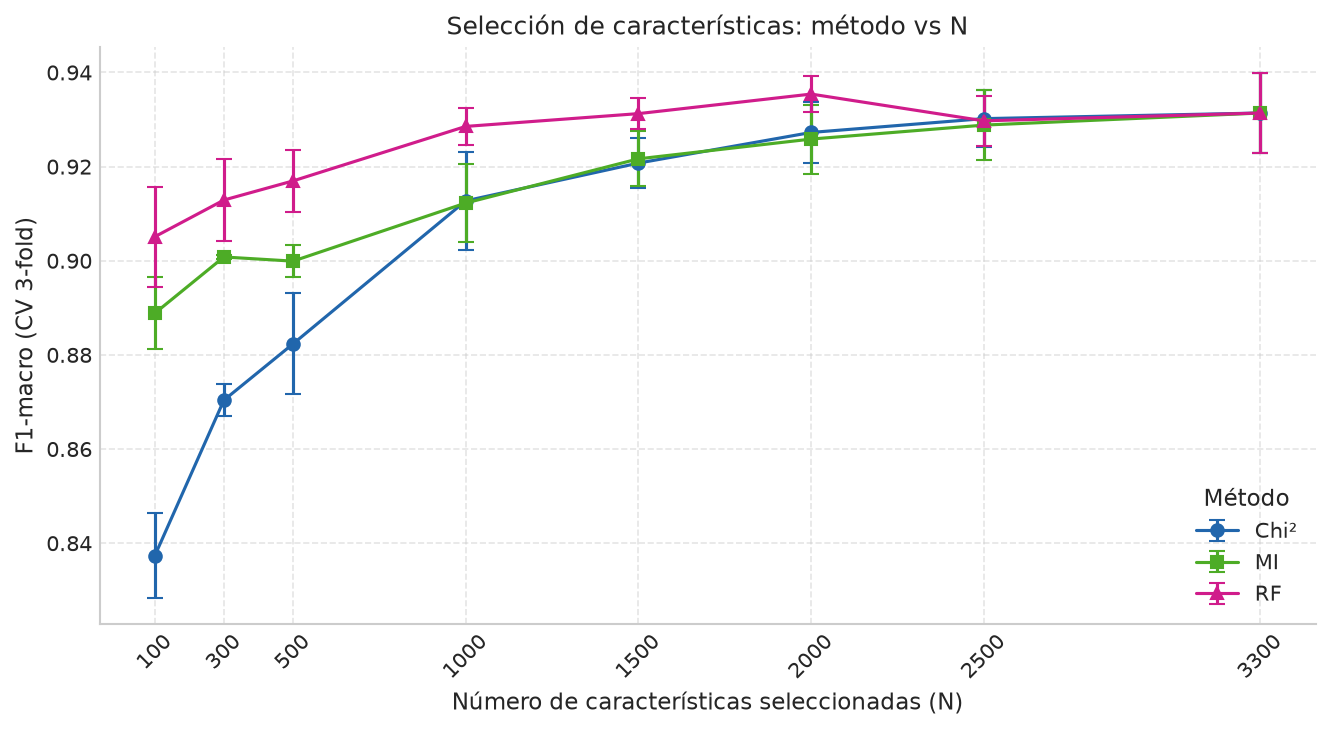

In [5]:
# Se grafican las curvas de F1-macro en función de N para los tres métodos.
# Las barras de error representan la desviación estándar entre los 3 folds.
# La curva completa (hasta N=3300) permite identificar visualmente el punto
# de estabilización del F1 y justificar la elección del N óptimo.

fig, ax = plt.subplots(figsize=(9, 5))

colors  = {'Chi2': '#2166AC', 'MI': '#4DAC26', 'RF': '#D01C8B'}
labels  = {'Chi2': 'Chi²',   'MI': 'MI',      'RF': 'RF'}
markers = {'Chi2': 'o',      'MI': 's',        'RF': '^'}

for method, grp in results_df.groupby('method'):
    ax.errorbar(
        grp['n'], grp['mean_f1'],
        yerr=grp['std_f1'],
        label=labels[method],
        color=colors[method],
        marker=markers[method],
        capsize=4,
        linewidth=1.5,
    )

ax.set_xlabel('Número de características seleccionadas (N)', fontsize=11)
ax.set_ylabel('F1-macro (CV 3-fold)', fontsize=11)
ax.set_title('Selección de características: método vs N', fontsize=12)
ax.legend(title='Método')
ax.set_xticks(N_VALUES)
ax.tick_params(axis='x', rotation=45)
ax.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
# fig.savefig('../reports/06_curva_seleccion.png', dpi=300, bbox_inches='tight')  # uncomment to save
plt.show()

## 5. Top-20 features por método y overlap entre métodos

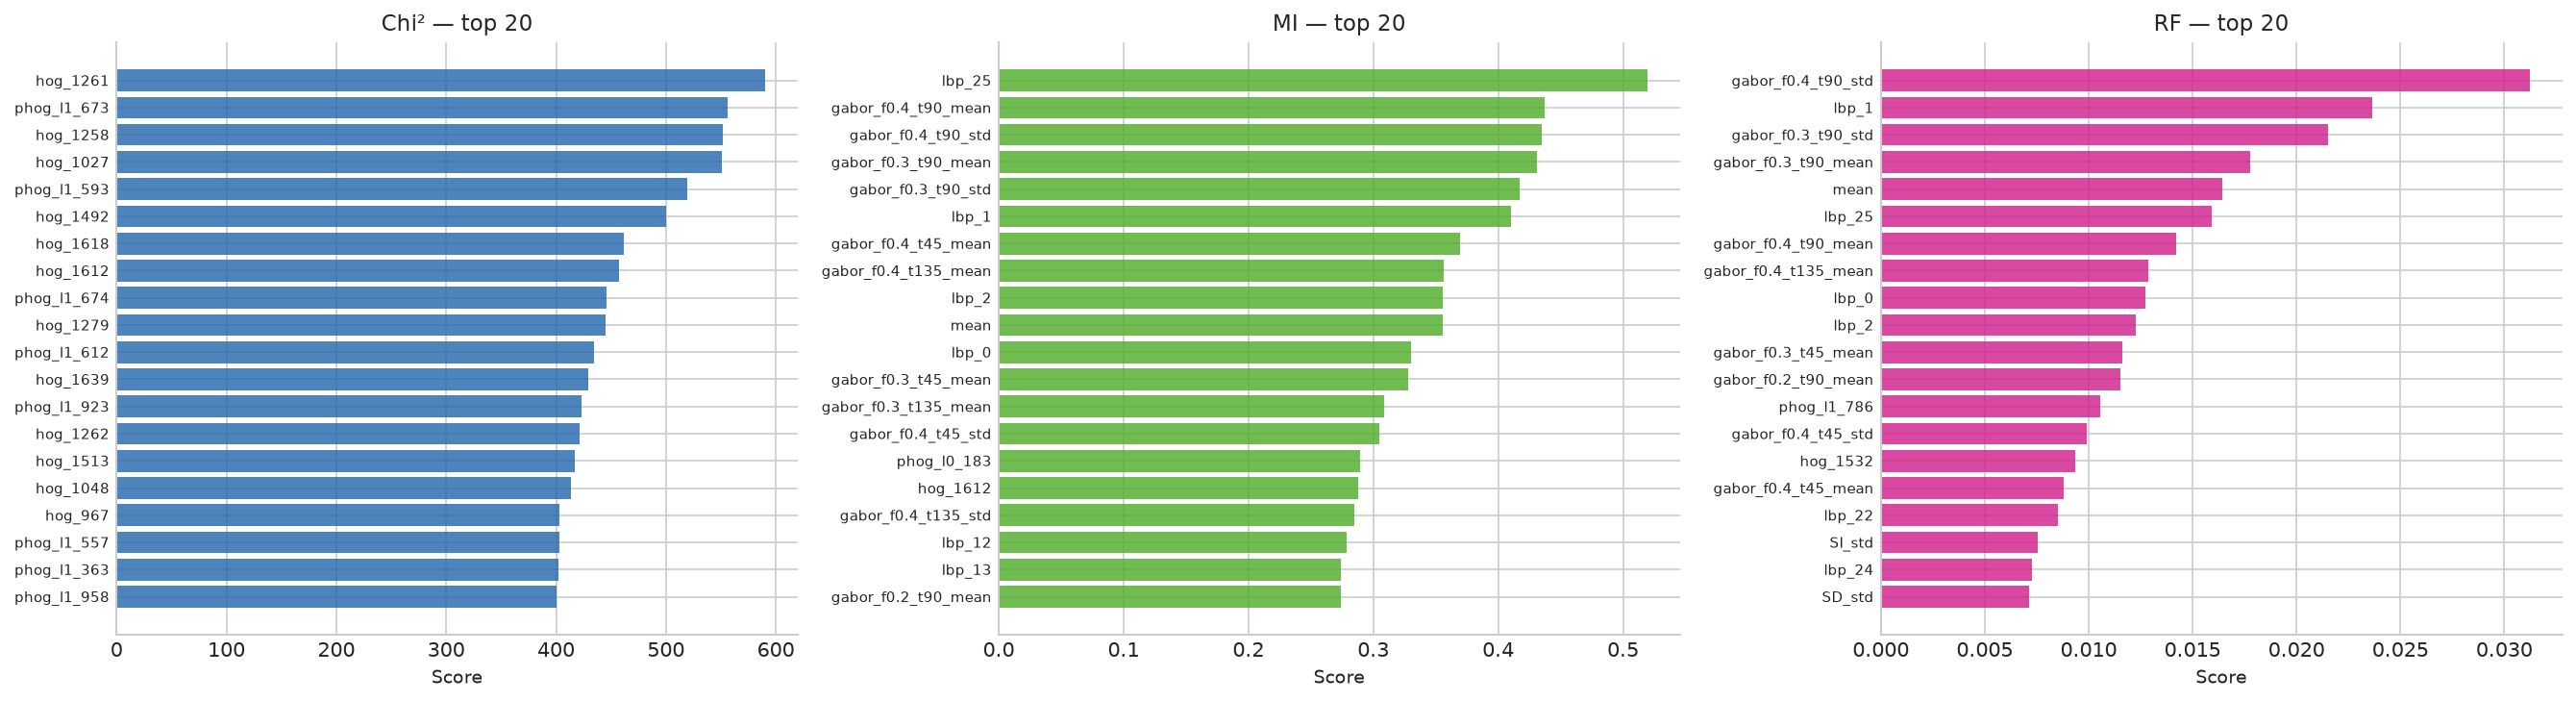

In [6]:
# Se grafican las 20 features con mayor score para cada método.
# Esto permite identificar qué grupos de features (HOG, GLCM, LBP, Gabor, PHOG)
# cada criterio considera más discriminativos.
#
# NOTA: estos scores se calculan sobre TODO el train, no dentro del CV.
# Su propósito es exploratorio/visual, no decisional.
# La decisión de qué método y N usar se tomó en la sección anterior.

# Chi² — score calculado sobre todo train (solo para visualización)
scaler_chi2 = MinMaxScaler().fit(X_train)
X_train_mm  = scaler_chi2.transform(X_train)
chi2_scores, _ = chi2(X_train_mm, y_train)
chi2_top20  = np.argsort(chi2_scores)[::-1][:20]

# Mutual Information — score calculado sobre todo train (solo para visualización)
mi_scores   = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
mi_top20    = np.argsort(mi_scores)[::-1][:20]

# RF importance — calculado sobre todo train (solo para visualización)
rf_vis = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_vis.fit(X_train, y_train)
rf_importances = rf_vis.feature_importances_
rf_ranking     = np.argsort(rf_importances)[::-1]
rf_top20       = rf_ranking[:20]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, top20, scores, title, color in [
    (axes[0], chi2_top20, chi2_scores,   'Chi² — top 20', '#2166AC'),
    (axes[1], mi_top20,  mi_scores,      'MI — top 20',   '#4DAC26'),
    (axes[2], rf_top20,  rf_importances, 'RF — top 20',   '#D01C8B'),
]:
    names  = [feat_cols[i] for i in top20]
    values = [scores[i]    for i in top20]
    y_pos  = range(len(names))
    ax.barh(y_pos, values[::-1], color=color, alpha=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(names[::-1], fontsize=7)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Score', fontsize=9)

fig.tight_layout()
# fig.savefig('../reports/06_top20_features.png', dpi=300, bbox_inches='tight')  # uncomment to save
plt.show()

In [7]:
# Se calcula el overlap entre los conjuntos de top-N features de cada método.
# Un overlap alto indica consenso entre criterios; un overlap bajo indica que
# cada criterio captura aspectos distintos del espacio de características.
# El overlap no determina qué método es mejor — eso lo decide el F1 del CV.
#
# NOTA: este análisis usa los scores calculados sobre todo el train.
# Es exploratorio; no cambia la decisión del método ganador.

print('Overlap entre métodos (features en común / N):')
print(f'  {"N":>6}  Chi2-MI  Chi2-RF  MI-RF  Chi2-MI-RF')
print('  ' + '-' * 50)

for n in N_VALUES:
    set_chi2 = set(np.argsort(chi2_scores)[::-1][:n].tolist())
    set_mi   = set(np.argsort(mi_scores)[::-1][:n].tolist())
    set_rf   = set(rf_ranking[:n].tolist())

    overlap_chi2_mi  = len(set_chi2 & set_mi)  / n
    overlap_chi2_rf  = len(set_chi2 & set_rf)  / n
    overlap_mi_rf    = len(set_mi   & set_rf)  / n
    overlap_all      = len(set_chi2 & set_mi & set_rf) / n

    print(f'  {n:>6}  {overlap_chi2_mi:.2f}     {overlap_chi2_rf:.2f}     {overlap_mi_rf:.2f}   {overlap_all:.2f}')

Overlap entre métodos (features en común / N):
       N  Chi2-MI  Chi2-RF  MI-RF  Chi2-MI-RF
  --------------------------------------------------
     100  0.39     0.31     0.67   0.21
     300  0.58     0.47     0.66   0.39
     500  0.69     0.50     0.64   0.45
    1000  0.78     0.56     0.65   0.51
    1500  0.84     0.63     0.66   0.57
    2000  0.86     0.70     0.73   0.63
    2500  0.89     0.80     0.80   0.73
    3300  1.00     1.00     1.00   1.00


## 6. Selección final: mejor método + N

In [8]:
# Se selecciona la combinación (método, N) con mayor F1-macro promedio en CV.
# En caso de empate se prefiere el N menor (menos features con igual desempeño).
#
# Esta elección está respaldada por la curva completa de N: si el máximo
# ocurre antes de N=3300, significa que añadir más características no mejora
# el desempeño con este evaluador, lo que justifica la reducción dimensional.

best_row = results_df.sort_values(
    ['mean_f1', 'n'], ascending=[False, True]
).iloc[0]

BEST_METHOD = best_row['method']
BEST_N      = int(best_row['n'])

print(f'Mejor combinación:')
print(f'  Método : {BEST_METHOD}')
print(f'  N      : {BEST_N}')
print(f'  F1-macro (CV) : {best_row["mean_f1"]:.4f} +/- {best_row["std_f1"]:.4f}')
print()
print('Tabla comparativa (media ± std por método):')
pivot = results_df.pivot(index='n', columns='method', values='mean_f1')
print(pivot.to_string())

Mejor combinación:
  Método : RF
  N      : 2000
  F1-macro (CV) : 0.9354 +/- 0.0039

Tabla comparativa (media ± std por método):
method      Chi2        MI        RF
n                                   
100     0.837340  0.888854  0.905110
300     0.870386  0.900807  0.912903
500     0.882343  0.899923  0.916966
1000    0.912730  0.912267  0.928544
1500    0.920756  0.921660  0.931263
2000    0.927265  0.925857  0.935417
2500    0.930199  0.928824  0.929727
3300    0.931392  0.931392  0.931392


In [9]:
# Se reajusta el selector ganador sobre TODO el train para obtener
# el subconjunto definitivo de features que se usará en el notebook 07.
#
# Los CSVs que se guardan contienen los valores ORIGINALES (sin escalar)
# de las features seleccionadas. El escalado es responsabilidad del
# notebook 07, que lo aplicará dentro de sus propios pipelines.

if BEST_METHOD == 'Chi2':
    # El selector necesita valores no negativos para ajustarse,
    # pero la máscara resultante se aplica sobre X original.
    scaler_final = MinMaxScaler().fit(X_train)
    X_train_mm   = scaler_final.transform(X_train)
    k_final      = 'all' if BEST_N == X_train.shape[1] else BEST_N
    selector_final = SelectKBest(chi2, k=k_final).fit(X_train_mm, y_train)
    selected_mask  = selector_final.get_support()
    X_train_sel    = X_train[:, selected_mask]   # valores originales
    X_test_sel     = X_test[:,  selected_mask]   # valores originales

elif BEST_METHOD == 'MI':
    k_final        = 'all' if BEST_N == X_train.shape[1] else BEST_N
    selector_final = SelectKBest(mutual_info_classif, k=k_final).fit(X_train, y_train)
    selected_mask  = selector_final.get_support()
    X_train_sel    = X_train[:, selected_mask]
    X_test_sel     = X_test[:,  selected_mask]

else:  # RF
    # RFTopNSelector garantiza exactamente BEST_N features, igual que en el CV.
    selector_final = RFTopNSelector(
        n_features=BEST_N,
        n_estimators=100,
        random_state=RANDOM_STATE,
    )
    selector_final.fit(X_train, y_train)
    X_train_sel   = selector_final.transform(X_train)
    X_test_sel    = selector_final.transform(X_test)
    selected_mask = np.zeros(X_train.shape[1], dtype=bool)
    selected_mask[selector_final.top_idx_] = True

selected_feature_names = [feat_cols[i] for i, m in enumerate(selected_mask) if m]

print(f'Features seleccionadas : {len(selected_feature_names)}')
print(f'Shape X_train_sel      : {X_train_sel.shape}')
print(f'Shape X_test_sel       : {X_test_sel.shape}')

Features seleccionadas : 2000
Shape X_train_sel      : (6720, 2000)
Shape X_test_sel       : (1680, 2000)


## 7. Guardado de los splits seleccionados

In [10]:
# Se guardan cinco archivos en data/ para que el notebook 07 arranque
# directamente sin recalcular nada:
#
#   X_train_selected.csv          — features train (solo las seleccionadas)
#   X_test_selected.csv           — features test  (solo las seleccionadas, reservado)
#   y_train.csv                   — etiquetas train
#   y_test.csv                    — etiquetas test  (reservado)
#   selected_feature_names.json   — lista de nombres de features seleccionadas

DATA_DIR = Path('..') / 'data'

pd.DataFrame(X_train_sel, columns=selected_feature_names).to_csv(
    DATA_DIR / 'X_train_selected.csv', index=False
)
pd.DataFrame(X_test_sel, columns=selected_feature_names).to_csv(
    DATA_DIR / 'X_test_selected.csv', index=False
)
pd.Series(y_train, name='label').to_csv(
    DATA_DIR / 'y_train.csv', index=False
)
pd.Series(y_test, name='label').to_csv(
    DATA_DIR / 'y_test.csv', index=False
)
with open(DATA_DIR / 'selected_feature_names.json', 'w') as f:
    json.dump(selected_feature_names, f, indent=2)

print('Archivos guardados en data/:')
print(f'  X_train_selected.csv        {X_train_sel.shape}')
print(f'  X_test_selected.csv         {X_test_sel.shape}  (reservado)')
print(f'  y_train.csv                 {y_train.shape}')
print(f'  y_test.csv                  {y_test.shape}  (reservado)')
print(f'  selected_feature_names.json {len(selected_feature_names)} features')
print()
print('Resumen de la selección:')
print(f'  Método elegido : {BEST_METHOD}')
print(f'  N elegido      : {BEST_N}')
print(f'  Features orig. : {X_train.shape[1]}')
print(f'  Features sel.  : {len(selected_feature_names)}')
print(f'  Reducción      : {100*(1 - len(selected_feature_names)/X_train.shape[1]):.1f} %')

Archivos guardados en data/:
  X_train_selected.csv        (6720, 2000)
  X_test_selected.csv         (1680, 2000)  (reservado)
  y_train.csv                 (6720,)
  y_test.csv                  (1680,)  (reservado)
  selected_feature_names.json 2000 features

Resumen de la selección:
  Método elegido : RF
  N elegido      : 2000
  Features orig. : 3300
  Features sel.  : 2000
  Reducción      : 39.4 %


## Conclusiones

Se evaluaron tres criterios de selección de características (Chi-cuadrado, Mutual Information
y Random Forest importance) sobre ocho valores de N que cubren el espectro completo, desde
100 hasta las 3300 características originales. Los tres métodos se evaluaron bajo las mismas
condiciones de validación cruzada (3 folds estratificados, evaluador LogisticRegression), con
el selector ajustado dentro de cada fold para evitar data leakage.

La combinación ganadora —impresa por la celda de selección final— es la que maximiza el
F1-macro promedio en validación cruzada; en caso de empate se prefiere el N menor, ya que
igual desempeño con menos características es preferible. La curva F1 vs N muestra dónde deja
de aportar añadir más características, lo que justifica la reducción de dimensionalidad.

Los archivos generados (X_train_selected.csv, X_test_selected.csv, y_train.csv, y_test.csv,
selected_feature_names.json) quedan listos para la siguiente etapa del pipeline (notebook 07).


**Siguiente etapa:** `07_Desbalanceo.ipynb`
